# OatEasy — Notebook 02: Model 1 — Dish Demand Predictor

**Question:** how many orders will each dish receive tomorrow?
**Data:** Dataset 1 (`dataset1_sales_demand.csv`) plus the calendar.
**Model:** gradient-boosted trees with Poisson loss (count data) for the central forecast, plus two quantile models (10th / 90th percentile) for an 80% uncertainty range.
**Baseline:** the seasonal-naive forecast (same dish, same weekday last week) and a 28-day moving average.

Leakage rule: every feature for day *t* uses only data up to *t−1*.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor

DATA = Path("../data"); MODELS = Path("../models"); OUT = Path("../outputs")
MODELS.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
TRAIN_END = pd.Timestamp("2025-06-30")

## 1. Load and explore Dataset 1

In [2]:
sales = pd.read_csv(DATA / "dataset1_sales_demand.csv", parse_dates=["date"])
cal = pd.read_csv(DATA / "calendar.csv", parse_dates=["date"])
print("rows:", sales.shape, "| dates:", sales.date.min().date(), "to", sales.date.max().date())
print("missing values:", int(sales.isna().sum().sum()))
print("dishes:", sales.dish_id.nunique(), "| restaurants:", sales.restaurant_id.nunique())
sales.describe().T[["mean", "std", "min", "max"]]

rows: (17544, 15) | dates: 2024-01-01 to 2025-12-31
missing values: 0
dishes: 12 | restaurants: 2


,mean,std,min,max
date,2024-12-31 00:00:00,NaN,2024-01-01 00:00:00,2025-12-31 00:00:00
is_weekend,0.284542,0.451209,0.0,1.0
month,6.519836,3.449649,1.0,12.0
list_price_inr,245.833333,97.081629,60.0,420.0
selling_price_inr,242.756213,96.264622,54.0,420.0
promo_flag,0.125171,0.330922,0.0,1.0
holiday_flag,0.021888,0.146321,0.0,1.0
avg_temp_c,24.891655,8.01139,9.6,40.0
rainfall_mm,1.583311,6.868613,0.0,91.4
units_sold,25.829001,14.60117,0.0,118.0


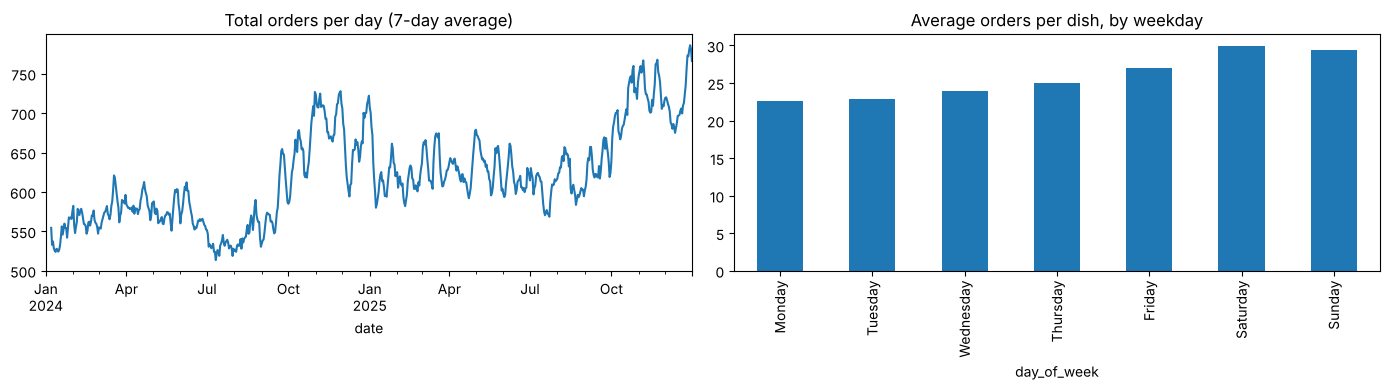

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sales.groupby("date").units_sold.sum().rolling(7).mean().plot(ax=ax[0], title="Total orders per day (7-day average)")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sales.groupby("day_of_week").units_sold.mean().reindex(order).plot.bar(ax=ax[1], title="Average orders per dish, by weekday")
plt.tight_layout(); plt.show()

## 2. Feature engineering

Features are computed per restaurant × dish. The lags and rolling means are shifted by one day so they only see past sales. The target row for the next day is appended with unknown units, so the same code produces the forecast features.

In [4]:
FORECAST_DATE = sales["date"].max() + pd.Timedelta(days=1)

def build_features(sales_df, cal_df, future_date=None):
    base = sales_df[["date", "restaurant_id", "dish_id", "dish_name", "category",
                     "list_price_inr", "selling_price_inr", "promo_flag", "holiday_flag",
                     "avg_temp_c", "rainfall_mm", "units_sold"]].copy()
    if future_date is not None:
        combos = base[["restaurant_id", "dish_id", "dish_name", "category", "list_price_inr"]].drop_duplicates()
        fut = combos.assign(date=future_date, selling_price_inr=combos["list_price_inr"],
                            promo_flag=0, rainfall_mm=0.0, units_sold=np.nan)
        c = cal_df.loc[cal_df["date"] == future_date].iloc[0]
        fut["holiday_flag"] = int(c["holiday_flag"])
        fut["avg_temp_c"] = float(c["temp_climatology_c"])   # weather-forecast placeholder
        base = pd.concat([base, fut], ignore_index=True)
    base = base.sort_values(["restaurant_id", "dish_id", "date"]).reset_index(drop=True)
    base = base.merge(cal_df[["date", "dow", "is_weekend", "month"]], on="date", how="left")

    g = base.groupby(["restaurant_id", "dish_id"])["units_sold"]
    base["lag_1"] = g.shift(1)
    base["lag_7"] = g.shift(7)
    base["lag_14"] = g.shift(14)
    base["roll_mean_7"] = g.transform(lambda s: s.shift(1).rolling(7, min_periods=3).mean())
    base["roll_mean_28"] = g.transform(lambda s: s.shift(1).rolling(28, min_periods=7).mean())

    base["restaurant_code"] = base["restaurant_id"].astype("category").cat.codes
    base["dish_code"] = base["dish_id"].astype("category").cat.codes
    base["category_code"] = base["category"].astype("category").cat.codes
    doy = base["date"].dt.dayofyear
    base["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    base["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    return base

FEATURES = ["restaurant_code", "dish_code", "category_code", "dow", "is_weekend", "month",
            "doy_sin", "doy_cos", "selling_price_inr", "promo_flag", "holiday_flag",
            "avg_temp_c", "rainfall_mm", "lag_1", "lag_7", "lag_14", "roll_mean_7", "roll_mean_28"]
CAT_FEATURES = ["restaurant_code", "dish_code", "category_code", "dow"]
cat_idx = [FEATURES.index(c) for c in CAT_FEATURES]

feat = build_features(sales, cal, FORECAST_DATE)
hist = feat[feat["units_sold"].notna() & feat["lag_1"].notna()].copy()
train = hist[hist["date"] <= TRAIN_END]
test = hist[hist["date"] > TRAIN_END]
future = feat[feat["date"] == FORECAST_DATE].copy()
print("train:", train.shape, "| test:", test.shape, "| forecast rows:", future.shape, "for", FORECAST_DATE.date())

train: (13104, 25) | test: (4416, 25) | forecast rows: (24, 25) for 2026-01-01


## 3. Train the models

In [5]:
common = dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
              l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
              n_iter_no_change=30, categorical_features=cat_idx, random_state=42)

mean_model = HistGradientBoostingRegressor(loss="poisson", **common).fit(train[FEATURES], train["units_sold"])
q10_model = HistGradientBoostingRegressor(loss="quantile", quantile=0.10, **common).fit(train[FEATURES], train["units_sold"])
q90_model = HistGradientBoostingRegressor(loss="quantile", quantile=0.90, **common).fit(train[FEATURES], train["units_sold"])
print("trees used (mean model):", mean_model.n_iter_)

trees used (mean model): 185


## 4. Evaluate on held-out data (after 2025-06-30) against baselines

In [6]:
def metrics(y, p):
    e = y - p
    return {"MAE": round(float(np.abs(e).mean()), 3),
            "RMSE": round(float(np.sqrt((e ** 2).mean())), 3),
            "WAPE": round(float(np.abs(e).sum() / y.sum()), 4),
            "Bias": round(float(e.mean()), 3)}

y = test["units_sold"].values
p_model = np.clip(mean_model.predict(test[FEATURES]), 0, None)
p_naive = test["lag_7"].fillna(test["roll_mean_28"]).fillna(test["lag_1"]).values
p_ma28 = test["roll_mean_28"].fillna(test["lag_1"]).values

results = pd.DataFrame({
    "seasonal_naive_lag7": metrics(y, p_naive),
    "moving_avg_28": metrics(y, p_ma28),
    "gbm_poisson (Model 1)": metrics(y, p_model),
}).T
results

,MAE,RMSE,WAPE,Bias
seasonal_naive_lag7,7.096,9.461,0.2542,0.228
moving_avg_28,5.693,7.651,0.2040,0.377
gbm_poisson (Model 1),4.901,6.517,0.1756,0.889


In [7]:
q10 = np.clip(q10_model.predict(test[FEATURES]), 0, None)
q90 = np.clip(q90_model.predict(test[FEATURES]), 0, None)
coverage = float(((y >= q10) & (y <= q90)).mean())
print(f"80% interval empirical coverage on test: {coverage:.1%} (target 80%)")

80% interval empirical coverage on test: 74.4% (target 80%)


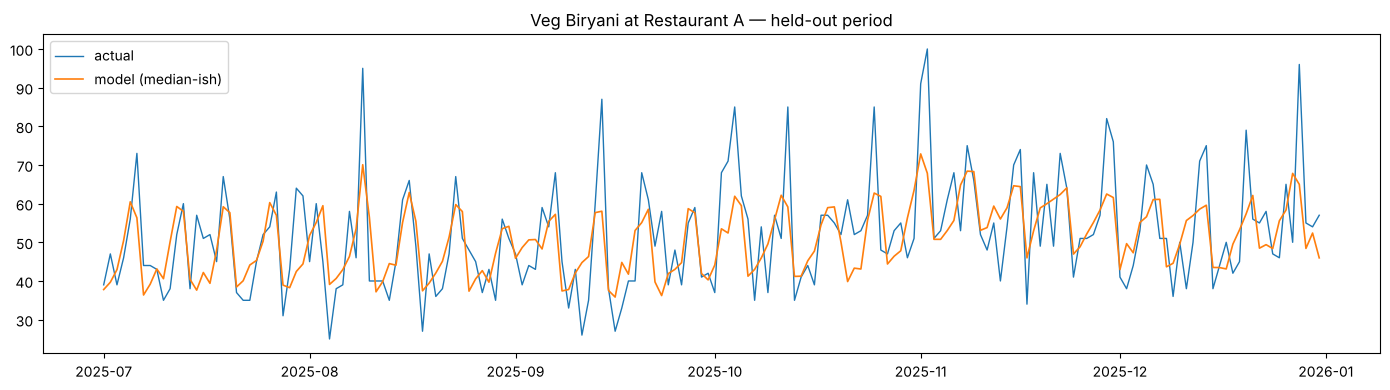

In [8]:
example = test[(test["restaurant_id"] == "R01") & (test["dish_id"] == "D03")].copy()
example["pred"] = np.clip(mean_model.predict(example[FEATURES]), 0, None)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(example["date"], example["units_sold"], label="actual", lw=1)
ax.plot(example["date"], example["pred"], label="model (median-ish)", lw=1.2)
ax.set_title("Veg Biryani at Restaurant A — held-out period")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Save models and metrics

In [9]:
joblib.dump(mean_model, MODELS / "model1_demand_mean_poisson.joblib")
joblib.dump(q10_model, MODELS / "model1_demand_q10.joblib")
joblib.dump(q90_model, MODELS / "model1_demand_q90.joblib")
json.dump({"features": FEATURES, "categorical_features": CAT_FEATURES,
           "train_end": str(TRAIN_END.date()), "forecast_date": str(FORECAST_DATE.date())},
          open(MODELS / "model1_config.json", "w"), indent=2)
metrics_out = {"test_metrics": results.to_dict(orient="index"), "interval_coverage_80": round(coverage, 4)}
json.dump(metrics_out, open(OUT / "metrics_model1.json", "w"), indent=2)
print("saved to", MODELS.resolve(), "and", OUT.resolve())

saved to /home/claude/OatEasy_ML/models and /home/claude/OatEasy_ML/outputs


## 6. Next-day forecast (feeds the decision engine)

Predicts the day after the last recorded sale. Rainfall is unknown in advance and set to 0; weather is the climatological temperature. Promotions are assumed off unless planned.

In [10]:
future["predicted_orders_median"] = np.clip(mean_model.predict(future[FEATURES]), 0, None).round(1)
future["lower_80"] = np.floor(np.clip(q10_model.predict(future[FEATURES]), 0, None))
future["upper_80"] = np.ceil(np.clip(q90_model.predict(future[FEATURES]), 0, None))
future["interval_width_ratio"] = ((future["upper_80"] - future["lower_80"]) / future["predicted_orders_median"].clip(lower=1)).round(2)
future["forecast_confidence"] = np.select(
    [future["interval_width_ratio"] < 0.6, future["interval_width_ratio"] < 1.2], ["High", "Medium"], "Low")

forecast = future[["date", "restaurant_id", "dish_id", "dish_name", "category",
                   "predicted_orders_median", "lower_80", "upper_80", "forecast_confidence"]].copy()
forecast["date"] = forecast["date"].dt.strftime("%Y-%m-%d")
forecast.to_csv(OUT / "forecast_next_day.csv", index=False)
forecast.sort_values(["restaurant_id", "predicted_orders_median"], ascending=[True, False])

,date,restaurant_id,dish_id,dish_name,category,predicted_orders_median,lower_80,upper_80,forecast_confidence
2927,2026-01-01,R01,D04,Butter Naan,Breads,69.6,48.0,79.0,High
2195,2026-01-01,R01,D03,Veg Biryani,Rice & Biryani,57.6,39.0,66.0,High
731,2026-01-01,R01,D01,Paneer Tikka,Starter,43.5,29.0,49.0,High
1463,2026-01-01,R01,D02,Dal Makhani,Main Course,41.7,29.0,49.0,High
4391,2026-01-01,R01,D06,Palak Paneer,Main Course,37.8,26.0,46.0,High
5123,2026-01-01,R01,D07,Jeera Rice,Rice & Biryani,36.7,23.0,44.0,High
3659,2026-01-01,R01,D05,Chole Bhature,Main Course,35.7,26.0,42.0,High
5855,2026-01-01,R01,D08,Masala Dosa,South Indian,32.6,24.0,42.0,High
6587,2026-01-01,R01,D09,Veg Thali,Combos,31.3,20.0,36.0,High
8051,2026-01-01,R01,D11,Gobi Manchurian,Starter,22.9,16.0,27.0,High
